# Лабораторная работа №2. Детекция мебели с YOLO26n на Android

**Мой вариант:** стул (`chair`), стол (`table`), кровать (`bed`), диван (`couch`).

Я использую готовый размеченный HomeObjects-3K, оставляю четыре нужных класса, дообучаю `yolo26n.pt` в Google Colab с GPU, оцениваю модель на валидационной части и экспортирую `best.tflite` для Android. Затем переношу результаты в локальный проект, собираю мобильное приложение и проверяю воспроизводимость обучения через Docker.

**Что считаю результатом работы:** `dataset/prepared`, обученный `runs/best.pt`, отчёт `runs/metrics.json`, модель `android/app/src/main/assets/best.tflite`, журналы обучения и исходный код в Git. Измерение скорости на физическом телефоне и итоговая оценка на *отдельном тестовом наборе* выполняются вне обучающей выборки.

У меня уже есть оригинальный архив `homeobjects-3K.zip` в Google Drive: `MyDrive/Lab2_Furniture/homeobjects-3K.zip`.


## 1. Подключаю Google Drive и открываю проект

Перед запуском включаю GPU в меню **Среда выполнения → Сменить среду выполнения → T4 GPU** (если он доступен). Затем запускаю ячейки строго сверху вниз.

Эта ячейка **не загружает проект повторно**, если он уже лежит в `/content`. В новом сеансе она автоматически копирует проект из распакованной папки на Drive. Если я предпочёл хранить исходники ZIP-файлом, она умеет взять ZIP с Drive вместо папки.


In [2]:
from pathlib import Path
import os, sys, json, subprocess, shutil, zipfile, hashlib, time
from datetime import datetime, timezone
from google.colab import drive

drive.mount('/content/drive')

ROOT = Path('/content/Lab2_YOLO26_Furniture')
DRIVE_BASE = Path('/content/drive/MyDrive/Lab2_Furniture')
HOMEOBJECTS_ZIP = DRIVE_BASE / 'homeobjects-3K.zip'
PREPARED_ARCHIVE = DRIVE_BASE / 'prepared.zip'
DATASET_DIR = ROOT / 'dataset/prepared'
DATA_YAML = DATASET_DIR / 'data.yaml'

def valid_project(folder):
    folder = Path(folder)
    return ((folder / 'scripts/train.py').is_file()
            and (folder / 'scripts/import_homeobjects.py').is_file()
            and (folder / 'scripts/export_litert.py').is_file()
            and (folder / 'android').is_dir())

def find_project(folder):
    folder = Path(folder)
    if not folder.is_dir():
        return None
    if valid_project(folder):
        return folder
    for child in folder.iterdir():
        if child.is_dir() and valid_project(child):
            return child
    return None

def safe_extract(archive, target_dir):
    target_dir = Path(target_dir).resolve()
    target_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            target = (target_dir / info.filename).resolve()
            if not target.is_relative_to(target_dir):
                raise ValueError('Небезопасный путь в ZIP: ' + info.filename)
            if ((info.external_attr >> 16) & 0o170000) == 0o120000:
                raise ValueError('Ссылки внутри ZIP не поддерживаются')
        z.extractall(target_dir)

if not HOMEOBJECTS_ZIP.is_file() and not PREPARED_ARCHIVE.is_file():
    raise FileNotFoundError('Нет ни homeobjects-3K.zip, ни prepared.zip в ' + str(DRIVE_BASE))

if valid_project(ROOT):
    print('Проект в Colab уже существует — повторное копирование не требуется.')
else:
    project_candidates = [
        DRIVE_BASE / 'project' / 'Lab2_YOLO26_Furniture',
        DRIVE_BASE / 'project',
        DRIVE_BASE / 'Lab2_YOLO26_Furniture',
        DRIVE_BASE / 'lab2',
    ]
    source = next((p for p in map(find_project, project_candidates) if p is not None), None)
    if source is not None:
        print('Копирую исходный проект из распакованной папки:', source, flush=True)
        shutil.copytree(source, ROOT, dirs_exist_ok=True)
    else:
        project_zips = [
            DRIVE_BASE / 'Lab2_YOLO26_HomeObjects_Fixed.zip',
            DRIVE_BASE / 'Lab2_YOLO26_HomeObjects_Ready.zip',
            DRIVE_BASE / 'project.zip',
        ]
        project_zip = next((p for p in project_zips if p.is_file()), None)
        if project_zip is None:
            raise FileNotFoundError(
                'Не найден проект. Скопируй распакованную папку Lab2_YOLO26_Furniture '
                'в Google Drive / Lab2_Furniture / project / и повтори ячейку.'
            )
        import tempfile
        with tempfile.TemporaryDirectory() as temp:
            safe_extract(project_zip, temp)
            source = find_project(temp)
            if source is None:
                raise RuntimeError('ZIP не содержит scripts/ и android/ в папке проекта.')
            shutil.copytree(source, ROOT, dirs_exist_ok=True)

if not valid_project(ROOT):
    raise RuntimeError('Код проекта не был найден в /content.')
os.chdir(ROOT)
(ROOT / 'runs').mkdir(exist_ok=True)
print('Рабочий каталог:', ROOT)
print('HomeObjects ZIP:', HOMEOBJECTS_ZIP if HOMEOBJECTS_ZIP.is_file() else 'Будет использован prepared.zip')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Копирую исходный проект из распакованной папки: /content/drive/MyDrive/Lab2_Furniture/project
Рабочий каталог: /content/Lab2_YOLO26_Furniture
HomeObjects ZIP: /content/drive/MyDrive/Lab2_Furniture/homeobjects-3K.zip


## 2. Подключаю Ultralytics и проверяю GPU

Я фиксирую **ту же версию исходников Ultralytics, что использовалась при моём предыдущем запуске**. Это позволяет сравнивать результаты с меньшим влиянием изменений самой библиотеки. Сначала библиотека устанавливается через `pip`, затем её исходный каталог добавляется в `sys.path` и `PYTHONPATH` — так я устраняю ошибку `ModuleNotFoundError` в текущем ядре и в дочерних скриптах.

Если GPU отсутствует, останавливаю работу на этом шаге: обучение 100 эпох на CPU заняло бы существенно больше времени. Дальше запускаю только при `CUDA: True`.


In [3]:
import importlib

ULTRA_PIN = 'c4e0ba9310ca5c567adb2b02f351f4d721557c71'  # коммит моего предыдущего запуска
SRC = ROOT / 'external/ultralytics'
SRC.parent.mkdir(parents=True, exist_ok=True)

if not (SRC / '.git').exists():
    if SRC.exists() and any(SRC.iterdir()):
        raise RuntimeError('external/ultralytics неполный. Удали только эту папку и повтори ячейку.')
    subprocess.run(['git', 'clone', '--depth=1', 'https://github.com/ultralytics/ultralytics.git', str(SRC)], check=True)

current_sha = subprocess.check_output(['git', '-C', str(SRC), 'rev-parse', 'HEAD'], text=True).strip()
if current_sha != ULTRA_PIN:
    print('Загружаю ранее использованный коммит Ultralytics...', flush=True)
    subprocess.run(['git', '-C', str(SRC), 'fetch', '--depth=1', 'origin', ULTRA_PIN], check=True)
    subprocess.run(['git', '-C', str(SRC), 'checkout', '--detach', ULTRA_PIN], check=True)

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(SRC)], check=True)

src_path = str(SRC.resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)
old_pythonpath = os.environ.get('PYTHONPATH', '')
if src_path not in old_pythonpath.split(os.pathsep):
    os.environ['PYTHONPATH'] = src_path + (os.pathsep + old_pythonpath if old_pythonpath else '')
importlib.invalidate_caches()

from ultralytics import YOLO
import ultralytics, torch, yaml

subprocess.run([sys.executable, '-c', 'from ultralytics import YOLO; print("Дочерний Python: YOLO импортирован")'], check=True)
ULTRA_SHA = subprocess.check_output(['git', '-C', str(SRC), 'rev-parse', 'HEAD'], text=True).strip()
(ROOT / 'runs/ultralytics_commit.txt').write_text(ULTRA_SHA + '\n', encoding='utf-8')
print('Ultralytics:', ultralytics.__version__, ULTRA_SHA)
print('CUDA:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('GPU недоступен. Включи T4 GPU в настройках Colab и снова запусти шаги 1–2.')
print('Видеокарта:', torch.cuda.get_device_name(0))


Загружаю ранее использованный коммит Ultralytics...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.202 c4e0ba9310ca5c567adb2b02f351f4d721557c71
CUDA: True
Видеокарта: Tesla T4


## 3. Подготавливаю размеченный набор данных

В HomeObjects-3K исходные номера: `0=bed`, `1=sofa`, `2=chair`, `3=table`, остальные — другие предметы. Мой Android-проект использует строго `0=chair`, `1=table`, `2=bed`, `3=couch`, поэтому требуется преобразование YOLO-разметки. Оригинальный `homeobjects-3K.zip` не изменяю.

Я сохраняю официальное разбиение набора на `train` и `val`. Если в Google Drive уже есть корректный `prepared.zip`, использую его и не обрабатываю исходные изображения повторно. Для принудительного импорта могу поставить `REBUILD_DATASET = True`.


In [4]:
from collections import Counter

REBUILD_DATASET = False  # меняю на True только если исходный ZIP/разметка изменились
EXPECTED_NAMES = ['chair', 'table', 'bed', 'couch']
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

def dataset_ready(folder):
    try:
        cfg = yaml.safe_load((folder / 'data.yaml').read_text(encoding='utf-8'))
        names = cfg['names']
        names = [names.get(i, names.get(str(i))) for i in range(4)] if isinstance(names, dict) else list(names)
        return (names == EXPECTED_NAMES and all(
            (folder / 'images' / s).is_dir() and (folder / 'labels' / s).is_dir()
            and any(p.suffix.lower() in IMAGE_EXTS for p in (folder / 'images' / s).rglob('*') if p.is_file())
            for s in ('train', 'val')
        ))
    except (OSError, KeyError, TypeError, ValueError):
        return False

if REBUILD_DATASET:
    if not HOMEOBJECTS_ZIP.is_file():
        raise FileNotFoundError('Для повторного импорта нужен исходный homeobjects-3K.zip.')
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)

if dataset_ready(DATASET_DIR):
    print('Набор уже подготовлен внутри проекта:', DATASET_DIR)
elif PREPARED_ARCHIVE.is_file() and not REBUILD_DATASET:
    print('Восстанавливаю prepared.zip из Google Drive...', flush=True)
    safe_extract(PREPARED_ARCHIVE, ROOT / 'dataset')
    if not dataset_ready(DATASET_DIR):
        raise RuntimeError('prepared.zip не подходит: проверь структуру и имена классов.')
else:
    print('Преобразую исходный HomeObjects-3K...', flush=True)
    subprocess.run([
        sys.executable, '-u', 'scripts/import_homeobjects.py',
        '--zip', str(HOMEOBJECTS_ZIP), '--out', str(DATASET_DIR),
    ], check=True)

if not dataset_ready(DATASET_DIR):
    raise RuntimeError('Подготовка изображений или разметки не завершилась.')

cfg = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))
cfg['path'] = str(DATASET_DIR.resolve())
cfg['train'] = 'images/train'
cfg['val'] = 'images/val'
DATA_YAML.write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True), encoding='utf-8')
container_cfg = dict(cfg, path='/workspace/dataset/prepared')
(DATASET_DIR / 'docker_data.yaml').write_text(
    yaml.safe_dump(container_cfg, sort_keys=False, allow_unicode=True), encoding='utf-8')

COUNTS = {}
for split in ('train', 'val'):
    folder = DATASET_DIR / 'images' / split
    imgs = [p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    labels = list((DATASET_DIR / 'labels' / split).rglob('*.txt'))
    objs = Counter()
    for label in labels:
        for line in label.read_text(encoding='utf-8').splitlines():
            if line.strip():
                cls = int(line.split()[0])
                if cls not in range(4):
                    raise ValueError('Некорректный класс в ' + str(label))
                objs[EXPECTED_NAMES[cls]] += 1
    COUNTS[split] = {'images': len(imgs), 'labels': len(labels), 'objects': dict(objs)}
    print(f'{split}: {len(imgs)} изображений, {len(labels)} аннотаций, объекты:', dict(objs))

# Отпечаток строю из имён и размеров фотографий, а также содержимого всех текстовых меток.
h = hashlib.sha256()
for p in sorted(DATASET_DIR.rglob('*')):
    if p.is_file() and (p.suffix.lower() in IMAGE_EXTS or p.suffix == '.txt'):
        h.update(str(p.relative_to(DATASET_DIR)).encode())
        h.update(str(p.stat().st_size).encode())
        if p.suffix == '.txt':
            h.update(p.read_bytes())
DATA_FINGERPRINT = h.hexdigest()
print('SHA256 описания датасета:', DATA_FINGERPRINT)
print('Папка с данными:', DATASET_DIR)


Восстанавливаю prepared.zip из Google Drive...
train: 2285 изображений, 2285 аннотаций, объекты: {'bed': 150, 'couch': 2074, 'table': 2561, 'chair': 2208}
val: 404 изображений, 404 аннотаций, объекты: {'chair': 305, 'table': 469, 'couch': 398, 'bed': 22}
SHA256 описания датасета: 0b4d15a7442f958547fc7462b2656ee6ccc42fe7419b1c4f1bac4f203e6311d4
Папка с данными: /content/Lab2_YOLO26_Furniture/dataset/prepared


### 3.1. Сохраняю подготовленные данные для Docker

`prepared.zip` содержит только преобразованные изображения, YOLO-метки и конфигурацию `data.yaml`. Это переносимая копия датасета. Мне не нужно заново скачивать и переразмечать оригинальные фотографии при каждом запуске Colab.


In [5]:
SAVE_PREPARED_AGAIN = REBUILD_DATASET
if PREPARED_ARCHIVE.is_file() and not SAVE_PREPARED_AGAIN:
    print('Архив уже сохранён в Google Drive:', PREPARED_ARCHIVE)
else:
    archive_tmp = ROOT / 'dataset/prepared.zip'
    print('Создаю prepared.zip из подготовленного набора...', flush=True)
    with zipfile.ZipFile(archive_tmp, 'w', compression=zipfile.ZIP_STORED) as z:
        for p in DATASET_DIR.rglob('*'):
            if p.is_file():
                z.write(p, p.relative_to(ROOT / 'dataset'))
    shutil.copy2(archive_tmp, PREPARED_ARCHIVE)
    print('Сохранено на Drive:', PREPARED_ARCHIVE)


Архив уже сохранён в Google Drive: /content/drive/MyDrive/Lab2_Furniture/prepared.zip


### 3.2. Проверяю, как выглядят рамки в разметке

Мне важно не только количество фотографий, но и корректность YOLO-меток. На одном изображении может быть несколько объектов. Пустой файл `.txt` означает, что после исключения других классов целевых объектов на нём не осталось. Для первого просмотра достаточно нарисовать рамки на нескольких тренировочных кадрах.


Фотография: train_living_room_1001_5aa03b6496.jpg


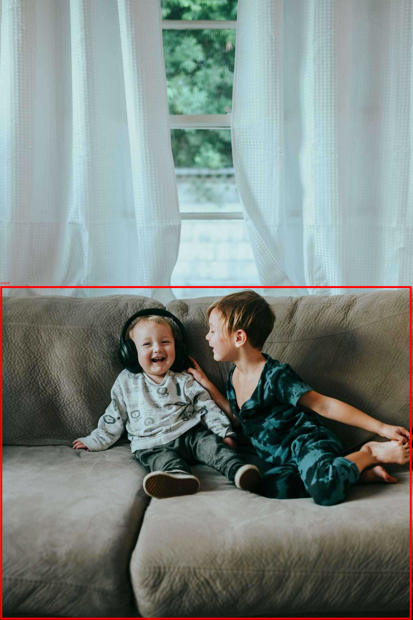

Фотография: train_living_room_1002_095b7db2a0.jpg


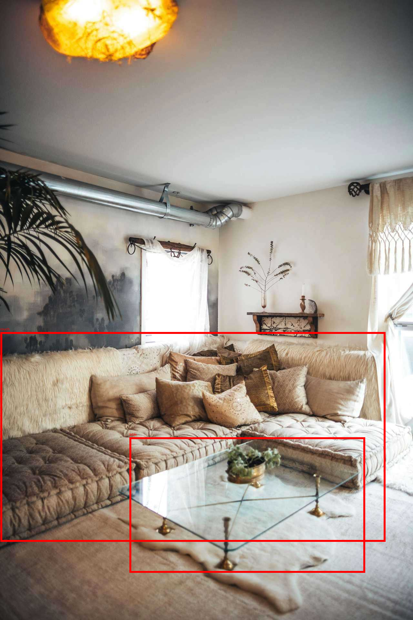

Фотография: train_living_room_1003_86bd0c0b67.jpg


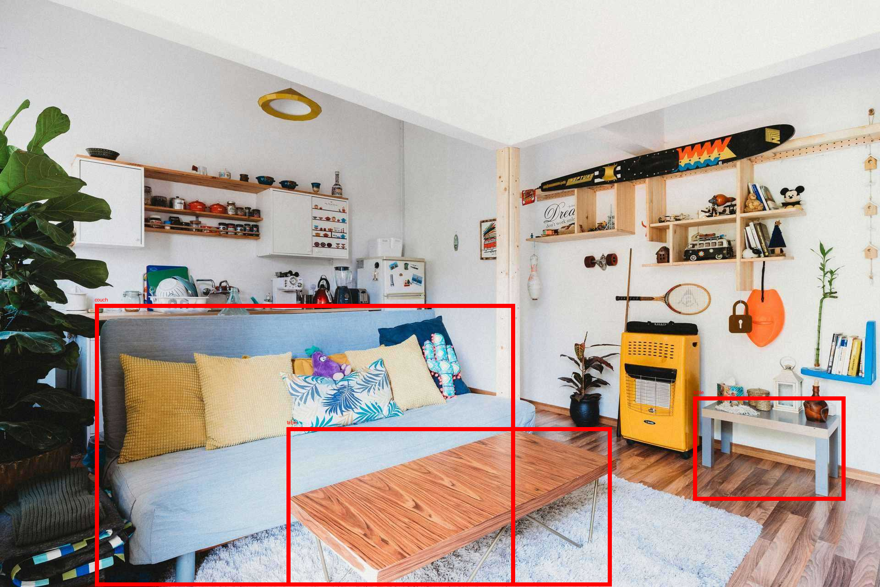

In [6]:
from PIL import Image, ImageDraw
from IPython.display import display

train_images = sorted(p for p in (DATASET_DIR / 'images/train').rglob('*') if p.suffix.lower() in IMAGE_EXTS)
shown = 0
for photo in train_images:
    label = DATASET_DIR / 'labels/train' / (photo.stem + '.txt')
    if not label.is_file() or not label.read_text(encoding='utf-8').strip():
        continue
    image = Image.open(photo).convert('RGB')
    W, H = image.size
    draw = ImageDraw.Draw(image)
    for line in label.read_text(encoding='utf-8').splitlines():
        cls, x, y, w, h = map(float, line.split())
        rect = ((x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H)
        draw.rectangle(rect, outline='red', width=max(2, W//200))
        draw.text((rect[0], max(0, rect[1]-16)), EXPECTED_NAMES[int(cls)], fill='red')
    image.thumbnail((880, 620))
    print('Фотография:', photo.name)
    display(image)
    shown += 1
    if shown >= 3:
        break
if not shown:
    raise RuntimeError('Не удалось найти изображения с целевой разметкой.')


## 4. Выбираю параметры обучения (единственная ячейка для настройки)

По предыдущему запуску стало понятно, что модель уже достигает порядка 0,80 mAP@0.5 на валидации, но `chair` распознаётся хуже остальных классов. Я **не запускаю автоматически вторую модель или вторую стадию**: сначала обучаю одну YOLO26n и сохраняю лучшую контрольную точку. Изменение только числа эпох не гарантирует рост качества, особенно когда срабатывает ранняя остановка.

Оставляю `imgsz=640` для соответствия экспортируемой Android-модели. `patience=25` даёт больше времени без улучшения, чем 12 эпох прошлого запуска, но обучение всё равно завершится раньше 100 эпох, если прогресс остановится. При нехватке памяти уменьшаю `BATCH` до 4. Для **нового самостоятельного эксперимента** меняю `RUN_ID`, не перезаписывая прежние результаты.


In [9]:
RUN_ID = 'furniture_yolo26n_640_v2'  # меняю только для нового независимого запуска
EPOCHS = 100
IMG_SIZE = 640
BATCH = 8
PATIENCE = 25
WORKERS = 2
SAVE_EVERY = 2
SEED = 42
FORCE_RESTART = False   # False: можно продолжить прерванное обучение

RUN_DIR = ROOT / 'runs' / RUN_ID
WEIGHTS_DIR = RUN_DIR / 'weights'
BEST_LOCAL = WEIGHTS_DIR / 'best.pt'
LAST_LOCAL = WEIGHTS_DIR / 'last.pt'
BEST = ROOT / 'runs/best.pt'
METRICS = ROOT / 'runs/metrics.json'
EXP_DRIVE = DRIVE_BASE / 'experiments' / RUN_ID
EXP_DRIVE.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR = EXP_DRIVE / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_LAST = CHECKPOINT_DIR / 'last.pt'
DRIVE_BEST = CHECKPOINT_DIR / 'best.pt'
DRIVE_METRICS = EXP_DRIVE / 'metrics.json'
CONFIG_FILE = EXP_DRIVE / 'config.json'
TRAIN_COMPLETED_MARKER = EXP_DRIVE / 'training_complete.json'

CONFIG = dict(run_id=RUN_ID, epochs=EPOCHS, imgsz=IMG_SIZE, batch=BATCH,
              patience=PATIENCE, workers=WORKERS, seed=SEED,
              ultralytics_commit=ULTRA_SHA, dataset_fingerprint=DATA_FINGERPRINT)

if CONFIG_FILE.exists():
    old_cfg = json.loads(CONFIG_FILE.read_text(encoding='utf-8'))
    if old_cfg != CONFIG:
        raise RuntimeError('Конфигурация отличается от сохранённой. Измени RUN_ID, чтобы начать новый эксперимент.')
else:
    CONFIG_FILE.write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False), encoding='utf-8')

print('Имя эксперимента:', RUN_ID)
print('GPU:', torch.cuda.get_device_name(0))
print('Эпохи:', EPOCHS, 'Размер:', IMG_SIZE, 'Batch:', BATCH, 'Early stopping:', PATIENCE)
print('Чекпоинты и итоговые файлы:', EXP_DRIVE)


Имя эксперимента: furniture_yolo26n_640_v2
GPU: Tesla T4
Эпохи: 100 Размер: 640 Batch: 8 Early stopping: 25
Чекпоинты и итоговые файлы: /content/drive/MyDrive/Lab2_Furniture/experiments/furniture_yolo26n_640_v2


## 5. Наблюдаю прогресс и сохраняю контрольные точки

Ultralytics отображает ход обучения по пакетам. Дополнительно после каждой **настоящей обучающей эпохи** печатаю mAP@0.5. Раньше прогресс показывал несуществующую дополнительную «83-ю эпоху», потому что итоговая валидация повторно вызвала callback `on_fit_epoch_end`. Здесь использую `on_model_save`: событие возникает при сохранении контрольной точки по завершении эпохи.

Через каждые `SAVE_EVERY` эпохи копирую `last.pt`, `best.pt` и `results.csv` в папку эксперимента на Drive. Если среда Colab отключится, следующий запуск этого блокнота сможет продолжить обучение с `last.pt` при неизменной конфигурации.


In [10]:
def backup_checkpoint(trainer, print_message=True):
    path = Path(trainer.save_dir) / 'weights'
    copied = []
    for name, dest in (('last.pt', DRIVE_LAST), ('best.pt', DRIVE_BEST)):
        src = path / name
        if src.is_file():
            tmp = dest.with_name(dest.name + '.uploading')
            shutil.copy2(src, tmp)
            os.replace(tmp, dest)
            copied.append(name)
    csv_src = Path(trainer.save_dir) / 'results.csv'
    if csv_src.is_file():
        shutil.copy2(csv_src, EXP_DRIVE / 'results.csv')
    if copied and print_message:
        print('Drive: сохранены ' + ', '.join(copied) + f' (эпоха {trainer.epoch + 1})', flush=True)

_seen_epochs = set()
def on_checkpoint_saved(trainer):
    epoch = int(trainer.epoch) + 1
    if epoch in _seen_epochs:
        return
    _seen_epochs.add(epoch)
    info = getattr(trainer, 'metrics', {}) or {}
    m = next((float(v) for k, v in info.items() if 'mAP50(B)' in k and '95' not in k), None)
    score = f'{m:.4f}' if m is not None else 'не получен'
    print(f'Эпоха {epoch}/{EPOCHS}; mAP@0.5 = {score}', flush=True)
    if epoch % SAVE_EVERY == 0:
        backup_checkpoint(trainer)

print('Прогресс включён. Контрольная точка каждые', SAVE_EVERY, 'эпохи.')


Прогресс включён. Контрольная точка каждые 2 эпохи.


## 6. Обучаю YOLO26n или продолжаю прерванный запуск

Эта ячейка выполняется дольше всех. Я вижу прогресс обучения в выводе. В конце сохраняю **лучшие веса `best.pt`**, а не просто последний `last.pt`: именно лучшая контрольная точка используется для валидации и последующего экспорта.

Запуск нового эксперимента *не зависит* от файлов старых экспериментов: у него отдельная папка `experiments/<RUN_ID>`. Если обучение уже было закончено и итоговые веса сохранены, ячейка восстановит их из Drive. Если вычисления были прерваны, попробует восстановить состояние с `last.pt`.


In [11]:
if FORCE_RESTART and (RUN_DIR.exists() or DRIVE_LAST.exists() or TRAIN_COMPLETED_MARKER.exists()):
    raise RuntimeError('Для полностью нового запуска выбери новый RUN_ID в шаге 4. Старые веса намеренно не удаляю.')

if TRAIN_COMPLETED_MARKER.is_file() and DRIVE_BEST.is_file():
    shutil.copy2(DRIVE_BEST, BEST)
    print('Обучение уже завершено ранее. Лучшие веса восстановлены:', BEST)
else:
    if DRIVE_LAST.is_file() and not LAST_LOCAL.is_file():
        WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy2(DRIVE_LAST, LAST_LOCAL)
        print('Восстановлен last.pt из Google Drive')

    resume = LAST_LOCAL.is_file()
    model = YOLO(str(LAST_LOCAL) if resume else 'yolo26n.pt')
    _seen_epochs.clear()
    model.add_callback('on_model_save', on_checkpoint_saved)
    print('Продолжение с checkpoint' if resume else 'Старт обучения с yolo26n.pt', flush=True)
    print('Прогресс Ultralytics будет отображаться ниже.', flush=True)

    if resume:
        model.train(resume=True)
    else:
        model.train(
            data=str(DATA_YAML.resolve()),
            epochs=EPOCHS, imgsz=IMG_SIZE, batch=BATCH, patience=PATIENCE,
            device=0, amp=True, workers=WORKERS, seed=SEED, deterministic=True,
            project=str((ROOT / 'runs').resolve()), name=RUN_ID, exist_ok=True,
            save=True, plots=True, verbose=True,
        )

    trainer = getattr(model, 'trainer', None)
    if trainer is not None:
        backup_checkpoint(trainer, print_message=False)
    if not BEST_LOCAL.is_file():
        raise FileNotFoundError('best.pt не создан. Проверь лог обучения выше.')
    shutil.copy2(BEST_LOCAL, BEST)
    shutil.copy2(BEST_LOCAL, DRIVE_BEST)
    TRAIN_COMPLETED_MARKER.write_text(json.dumps({
        'finished_utc': datetime.now(timezone.utc).isoformat(),
        'run_id': RUN_ID,
        'best_checkpoint': str(DRIVE_BEST),
    }, indent=2, ensure_ascii=False), encoding='utf-8')
    print('Обучение завершено. Лучшие веса:', BEST)

print('Лучшие веса доступны:', BEST, '|', round(BEST.stat().st_size / 1024**2, 2), 'MiB')


Старт обучения с yolo26n.pt
Прогресс Ultralytics будет отображаться ниже.
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Lab2_YOLO26_Furniture/dataset/prepared/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum

## 7. Проверяю mAP@0.5 и результаты каждого класса

Метрика **mAP@0.5 по всем четырём классам** — это среднее по классам, а не минимум по классам. Поэтому общий результат может быть выше 0,8 даже тогда, когда `chair` ниже 0,8. В протокол записываю общий mAP@0.5, mAP@0.5:0.95 и показатели каждого класса. Проверка здесь проводится на исходном `val` HomeObjects-3K, а не на неизвестном независимом тесте.

**Моя предыдущая проверка (не новый результат):** общий mAP@0.5 = 0,8027, `chair` = 0,724, `table` = 0,803, `bed` = 0,816, `couch` = 0,868. На валидации было только 22 объекта `bed`, поэтому оценка этого класса менее устойчива. После новой тренировки я использую только значения, полученные в ячейке ниже.


In [12]:
if not BEST.is_file():
    if DRIVE_BEST.is_file():
        shutil.copy2(DRIVE_BEST, BEST)
    else:
        raise FileNotFoundError('Нужен best.pt из шага 6.')

if DRIVE_METRICS.is_file() and TRAIN_COMPLETED_MARKER.is_file():
    shutil.copy2(DRIVE_METRICS, METRICS)
    summary = json.loads(METRICS.read_text(encoding='utf-8'))
    print('Уже рассчитанные метрики восстановлены с Drive.')
else:
    print('Вычисляю метрики на validation-разделе...', flush=True)
    result = YOLO(str(BEST)).val(
        data=str(DATA_YAML.resolve()), split='val', imgsz=IMG_SIZE,
        batch=BATCH, device=0, plots=True,
        project=str((ROOT / 'runs').resolve()), name='validation_' + RUN_ID,
        exist_ok=True,
    )
    cls_ids = [int(i) for i in result.box.ap_class_index]
    cls_ap = [float(i) for i in result.box.ap50]
    per_class = {EXPECTED_NAMES[i]: None for i in range(4)}
    for i, ap in zip(cls_ids, cls_ap):
        if i in range(4):
            per_class[EXPECTED_NAMES[i]] = ap
    summary = {
        'run_id': RUN_ID,
        'map50_validation': float(result.box.map50),
        'map50_95_validation': float(result.box.map),
        'precision_mean': float(result.box.mp),
        'recall_mean': float(result.box.mr),
        'ap50_per_class': per_class,
        'dataset_counts': COUNTS,
        'dataset_fingerprint': DATA_FINGERPRINT,
        'epochs_requested': EPOCHS,
        'image_size': IMG_SIZE,
        'batch': BATCH,
        'ultralytics_commit': ULTRA_SHA,
    }
    METRICS.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    shutil.copy2(METRICS, DRIVE_METRICS)

print(json.dumps(summary, ensure_ascii=False, indent=2))
print('Валидационный mAP@0.5:', round(summary['map50_validation'], 4))
if summary['map50_validation'] >= 0.8:
    print('На validation общий mAP@0.5 достиг 0,8. Отдельный тест ещё не выполнен.')
else:
    print('На validation общий mAP@0.5 ниже 0,8; нужно изучить ошибки по классам.')


Вычисляю метрики на validation-разделе...
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3406.9±941.2 MB/s, size: 209.9 KB)
val: Scanning /content/Lab2_YOLO26_Furniture/dataset/prepared/labels/val.cache... 404 images, 25 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 404/404 130.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 7.6it/s 6.7s
                   all        404       1194      0.799      0.725      0.803      0.588
                 chair        154        305      0.748      0.728      0.724      0.495
                 table        300        469       0.79      0.731      0.803      0.597
                   bed         22         22      0.781      0.648      0.816      0.607
                 couch        286        398      0.876     

## 8. Экспортирую лучший checkpoint в LiteRT для Android

Для мобильного приложения нужен **не** `.pt`, а `best.tflite`. Я экспортирую только обученную четырёхклассовую модель и проверяю фактические формы тензоров. В моём предыдущем успешном экспорте вход имел форму `[1,3,640,640]` (NCHW), выход — `[1,8,8400]`. Новый экспорт должен быть проверен отдельно; я не предполагаю формат по имени файла.

В проекте должен использоваться Android-детектор из исправленного архива `Lab2_YOLO26_HomeObjects_Fixed.zip`, поскольку он поддерживает NCHW и NHWC.


In [13]:
if not BEST.is_file():
    raise FileNotFoundError('Сначала нужны лучшие веса best.pt из шага 6.')

MODEL = ROOT / 'android/app/src/main/assets/best.tflite'
EXPORT_META = EXP_DRIVE / 'export_info.json'

best_hash = hashlib.sha256(BEST.read_bytes()).hexdigest()
export_id = {'best_pt_sha256': best_hash, 'imgsz': 640}
existing = json.loads(EXPORT_META.read_text(encoding='utf-8')) if EXPORT_META.exists() else {}
if MODEL.is_file() and all(existing.get(k) == v for k, v in export_id.items()):
    print('Экспорт этой версии весов уже выполнен:', MODEL)
else:
    print('Создаю LiteRT из best.pt...', flush=True)
    subprocess.run([
        sys.executable, '-u', 'scripts/export_litert.py',
        '--weights', str(BEST),
        '--assets', str(MODEL.parent),
        '--imgsz', '640',
    ], check=True)

if not MODEL.is_file():
    raise FileNotFoundError('Экспорт завершился без файла best.tflite.')
labels = (MODEL.parent / 'labels.txt').read_text(encoding='utf-8').splitlines()
assert labels == EXPECTED_NAMES, f'Не совпадают классы Android: {labels}'

shape_report = {'input_shape': None, 'output_shape': None}
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    try:
        from tensorflow.lite import Interpreter
    except ImportError:
        Interpreter = None
if Interpreter is not None:
    interpreter = Interpreter(model_path=str(MODEL))
    interpreter.allocate_tensors()
    in_info = interpreter.get_input_details()[0]
    out_info = interpreter.get_output_details()[0]
    shape_report = {
        'input_shape': [int(v) for v in in_info['shape']],
        'output_shape': [int(v) for v in out_info['shape']],
        'input_dtype': str(in_info['dtype']),
        'output_dtype': str(out_info['dtype']),
    }
    print('Вход LiteRT:', shape_report['input_shape'], shape_report['input_dtype'])
    print('Выход LiteRT:', shape_report['output_shape'], shape_report['output_dtype'])
    if shape_report['input_shape'] not in ([1,3,640,640], [1,640,640,3]):
        raise RuntimeError('Неподдерживаемая Android-кодом форма входного тензора.')
    if shape_report['output_shape'] not in ([1,8,8400], [1,8400,8]):
        print('Форма выхода отличается от типичной; проверь совместимость Android-кода.')
else:
    print('Нет локального LiteRT/TensorFlow-интерпретатора для проверки форм; смотри Logcat на телефоне.')

export_summary = dict(**export_id, model_file=str(MODEL), model_bytes=MODEL.stat().st_size,
                      labels=labels, **shape_report)
EXPORT_META.write_text(json.dumps(export_summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Модель подготовлена:', MODEL, 'размер:', round(MODEL.stat().st_size / 1024**2, 2), 'MiB')


Создаю LiteRT из best.pt...
Вход LiteRT: [1, 3, 640, 640] <class 'numpy.float32'>
Выход LiteRT: [1, 8, 8400] <class 'numpy.float32'>
Модель подготовлена: /content/Lab2_YOLO26_Furniture/android/app/src/main/assets/best.tflite размер: 9.44 MiB


## 9. Сохраняю всё необходимое для локального проекта

Я не переношу вручную тысячи фотографий из `/content`. Два результата забираю из Google Drive:

- `MyDrive/Lab2_Furniture/prepared.zip` — подготовленный датасет для Docker и повторного обучения.
- `MyDrive/Lab2_Furniture/experiments/<RUN_ID>/results_bundle.zip` — обученные веса, отчёты, кривые обучения и готовая LiteRT-модель.

Оригинальный `homeobjects-3K.zip` остаётся неизменным на Drive; в `results_bundle.zip` он не дублируется. Мой проект на компьютере по-прежнему находится в `C:\Mehmat\FIIT\2 course\1 sem\Neiro\lab2\Lab2_YOLO26_Furniture`.


In [14]:
if not BEST.is_file() or not MODEL.is_file() or not METRICS.is_file():
    raise RuntimeError('Нужны best.pt, best.tflite и metrics.json — заверши шаги 6–8.')

bundle = ROOT / 'results_bundle.zip'
with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=1) as z:
    for folder in (ROOT / 'runs', ROOT / 'android/app/src/main/assets'):
        for f in sorted(folder.rglob('*')):
            if f.is_file():
                z.write(f, f.relative_to(ROOT))
    z.writestr('experiment_info.json', json.dumps({
        'run_id': RUN_ID,
        'config': CONFIG,
        'dataset_counts': COUNTS,
        'export_info': json.loads(EXPORT_META.read_text(encoding='utf-8')),
    }, indent=2, ensure_ascii=False))

BUNDLE_DRIVE = EXP_DRIVE / 'results_bundle.zip'
shutil.copy2(bundle, BUNDLE_DRIVE)
shutil.copy2(BEST, EXP_DRIVE / 'best.pt')
shutil.copy2(MODEL, EXP_DRIVE / 'best.tflite')
print('ГОТОВО. Скачиваю на компьютер из Google Drive:')
print('  Датасет:', PREPARED_ARCHIVE)
print('  Результаты:', BUNDLE_DRIVE)
print('  Итоговая модель:', EXP_DRIVE / 'best.tflite')
print('Размер архива результатов:', round(bundle.stat().st_size / 1024**2, 2), 'MiB')


ГОТОВО. Скачиваю на компьютер из Google Drive:
  Датасет: /content/drive/MyDrive/Lab2_Furniture/prepared.zip
  Результаты: /content/drive/MyDrive/Lab2_Furniture/experiments/furniture_yolo26n_640_v2/results_bundle.zip
  Итоговая модель: /content/drive/MyDrive/Lab2_Furniture/experiments/furniture_yolo26n_640_v2/best.tflite
Размер архива результатов: 38.78 MiB


## 10. Переношу файлы из Google Drive в Windows-проект

1. Скачиваю `prepared.zip` и `experiments/<RUN_ID>/results_bundle.zip` в `C:\Mehmat\FIIT\2 course\1 sem\Neiro\lab2\01_Результаты_Colab`.
2. Распаковываю `prepared.zip` **в папку `Lab2_YOLO26_Furniture\dataset`**. В итоге должен появиться `Lab2_YOLO26_Furniture\dataset\prepared\data.yaml`.
3. Распаковываю `results_bundle.zip` **в корень `Lab2_YOLO26_Furniture`**. В итоге получаю `Lab2_YOLO26_Furniture\runs\best.pt` и `Lab2_YOLO26_Furniture\android\app\src\main\assets\best.tflite`.

Для PowerShell удобно выполнить две команды, находясь в папке `lab2`:

```powershell
Expand-Archive -LiteralPath '.\01_Результаты_Colab\prepared.zip' -DestinationPath '.\Lab2_YOLO26_Furniture\dataset' -Force
Expand-Archive -LiteralPath '.\01_Результаты_Colab\results_bundle.zip' -DestinationPath '.\Lab2_YOLO26_Furniture' -Force
```

Проверяю локальную структуру:

```text
lab2/Lab2_YOLO26_Furniture/
├── dataset/prepared/images/train/
├── dataset/prepared/images/val/
├── dataset/prepared/labels/train/
├── dataset/prepared/labels/val/
├── dataset/prepared/data.yaml
├── dataset/prepared/docker_data.yaml
├── runs/best.pt
├── runs/metrics.json
├── android/app/src/main/assets/best.tflite
└── android/app/src/main/assets/labels.txt
```

Данные для Docker теперь доступны **на компьютере**. В Google Colab Docker запускать не нужно.


## 11. Собираю Android-приложение и проверяю Docker на Windows

### Android Studio

1. Открываю **`Lab2_YOLO26_Furniture/android`**, а не папку `lab2` целиком.
2. В терминале PowerShell внутри `android` один раз выполняю:

   ```powershell
   powershell -ExecutionPolicy Bypass -File .\bootstrap_gradle_windows.ps1
   ```

3. В Android Studio делаю **Sync Project with Gradle Files**, проверяю наличие `app/src/main/assets/best.tflite` и `labels.txt`, собираю debug APK.
4. Подключаю смартфон с включённой отладкой по USB, выбираю его в Android Studio и нажимаю **Run**.
5. В приложении открываю тестовые фотографии мебели, проверяю рамки и выполняю профилирование. Сохраняю CSV с реальным временем `Interpreter.run()` и скриншоты обнаружения четырёх классов.

### Docker Desktop + Git

Docker запускаю **на компьютере**, не в Google Colab. Устанавливаю Docker Desktop и Git, запускаю Docker Desktop, затем в PowerShell:

```powershell
cd 'C:\Mehmat\FIIT\2 course\1 sem\Neiro\lab2\Lab2_YOLO26_Furniture'
.\setup_git.bat
git submodule status
```

Фиксирую в submodule ту же версию Ultralytics, что была при обучении (её хеш сохранён в `runs/ultralytics_commit.txt`):

```powershell
$sha = (Get-Content '.\runs\ultralytics_commit.txt').Trim()
git -C 'external/ultralytics' fetch origin $sha
git -C 'external/ultralytics' checkout $sha
```

Собираю Docker-образ:

```powershell
docker info
docker build -t lab2-yolo26 .
New-Item -ItemType Directory -Force -Path 'runs-docker'
```

Проверяю одну эпоху на CPU (это **только тест запуска контейнера**, не новое полноценное обучение модели):

```powershell
docker run --rm `
  -v "${PWD}/dataset/prepared:/workspace/dataset/prepared:ro" `
  -v "${PWD}/runs-docker:/workspace/runs" `
  lab2-yolo26 `
  --data /workspace/dataset/prepared/docker_data.yaml `
  --runs /workspace/runs `
  --device cpu `
  --epochs 1 `
  --batch 2
```

Контейнер должен читать данные из `dataset/prepared`, а результаты сохранять в `runs-docker`. Для полного воспроизводимого обучения требуются те же гиперпараметры и GPU-окружение, что в Colab. В текущем блокноте я **не запускаю дополнительный эксперимент**.

### GitHub

Публикую исходники, `Dockerfile`, `.gitmodules`, конфигурацию и небольшие отчёты. Тяжёлый исходный датасет доступен по публичной ссылке HomeObjects-3K; веса и полные логи можно поместить в GitHub Release. Проверяю, что `git submodule status` отображает оба источника.


## 12. Оценка на независимой тестовой выборке

Валидационный результат шага 7 не равен результату на новом наборе изображений. Для окончательной оценки готовлю отдельные `images/test`, `labels/test` и `test.yaml` **с тем же порядком четырёх классов**, после чего запускаю `scripts/evaluate_test.py` с `runs/best.pt`.

```python
subprocess.run([
    sys.executable, 'scripts/evaluate_test.py',
    '--weights', 'runs/best.pt',
    '--test-data', 'dataset/instructor_test/test.yaml'
], check=True)
```

Если точность на новом тесте окажется недостаточной, сначала анализирую ошибочные примеры и дополняю **только тренировочную** часть новыми достоверно размеченными изображениями. Не подмешиваю тест в обучение и не делаю автоматическую повторную тренировку без анализа.

**Итог:** один воспроизводимый запуск → лучшая модель → проверка на validation → LiteRT → Android → отдельная тестовая оценка.
